<a href="https://colab.research.google.com/github/srimathi23-lgtm/datascience-lab/blob/main/ds_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# Exp 1
import csv
import json
import os
import pandas as pd

# Create data folder
os.makedirs("data", exist_ok=True)


# ---------- Step 1: Data Collection from Three Different Sources ----------

# Source 1: CSV file from the in-store billing (POS) system
pos_rows = [
    ["order_id", "customer", "product", "qty", "unit_price", "branch"],
    [101, "Anitha", "Laptop", 1, 54000, "Chennai"],
    [102, "Rahul", "Mouse", 3, 450, "Chennai"],
    [103, "Priya", "Keyboard", 2, 1200, "Chennai"],
    [104, "Karthik", "Monitor", 1, 9500, "Chennai"],
]

with open("data/pos_orders.csv", "w", newline="") as f:
    csv.writer(f).writerows(pos_rows)


# Source 2: JSON response from the online store (Web API)
web_orders = [
    {
        "order_id": 201,
        "customer": "Divya",
        "product": "Laptop",
        "qty": 2,
        "unit_price": 52500,
        "branch": "Online",
    },
    {
        "order_id": 202,
        "customer": "Arjun",
        "product": "Headset",
        "qty": 1,
        "unit_price": 2300,
        "branch": "Online",
    },
    {
        "order_id": 203,
        "customer": "Meena",
        "product": "Mouse",
        "qty": 5,
        "unit_price": 430,
        "branch": "Online",
    },
]

with open("data/web_orders.json", "w") as f:
    json.dump(web_orders, f, indent=2)


# Source 3: Plain-text log from the mobile app (Pipe Separated)
log_lines = [
    "301|Suresh|Monitor|2|9300|Mobile",
    "302|Lakshmi|Keyboard|1|1150|Mobile",
    "303|Vignesh|Laptop|1|55000|Mobile",
]

with open("data/mobile_orders.txt", "w") as f:
    f.write("\n".join(log_lines))


print("Retail Order Data: Collection, Storage and Retrieval")
print("=" * 55)


# ---------- Step 2: Reading Data from Each File ----------

# Read CSV data
df_pos = pd.read_csv("data/pos_orders.csv")

print("\n[1] CSV Source -> Rows:", len(df_pos))
print(df_pos.to_string(index=False))


# Read JSON data
with open("data/web_orders.json") as f:
    df_web = pd.DataFrame(json.load(f))

print("\n[2] JSON Source -> Rows:", len(df_web))
print(df_web.to_string(index=False))


# Read TXT data
cols = [
    "order_id",
    "customer",
    "product",
    "qty",
    "unit_price",
    "branch",
]

df_mob = pd.read_csv(
    "data/mobile_orders.txt",
    sep="|",
    header=None,
    names=cols
)

print("\n[3] TXT Source -> Rows:", len(df_mob))
print(df_mob.to_string(index=False))


# ---------- Step 3: Integration into a Single Dataset ----------

orders = pd.concat(
    [df_pos, df_web, df_mob],
    ignore_index=True
)

# Calculate total order amount
orders["amount"] = orders["qty"] * orders["unit_price"]

print("\n--- Integrated Dataset ---")
print(orders.to_string(index=False))

print("\nShape:", orders.shape)

print("Data Types:")
print(orders.dtypes.to_string())


# ---------- Step 4: Storage in Different Formats ----------

orders.to_csv("data/all_orders.csv", index=False)

orders.to_json(
    "data/all_orders.json",
    orient="records",
    indent=2
)

orders.to_excel(
    "data/all_orders.xlsx",
    index=False
)

print("\nFiles Stored:")

for name in [
    "all_orders.csv",
    "all_orders.json",
    "all_orders.xlsx",
]:
    file_size = os.path.getsize("data/" + name)

    print(f"  data/{name:<16} {file_size:>6} bytes")


# ---------- Step 5: Retrieval and Quick Query ----------

# Retrieve data from Excel
back = pd.read_excel("data/all_orders.xlsx")

print("\nRetrieved from Excel, Rows:", len(back))


# Calculate revenue by branch
print("\nRevenue by Branch:")

print(
    back.groupby("branch")["amount"]
    .sum()
    .sort_values(ascending=False)
    .to_string()
)


# Display orders with amount greater than 10000
print("\nOrders with Amount > 10000:")

print(
    back.loc[
        back["amount"] > 10000,
        ["order_id", "customer", "product", "amount"]
    ].to_string(index=False)
)

Retail Order Data: Collection, Storage and Retrieval

[1] CSV Source -> Rows: 4
 order_id customer  product  qty  unit_price  branch
      101   Anitha   Laptop    1       54000 Chennai
      102    Rahul    Mouse    3         450 Chennai
      103    Priya Keyboard    2        1200 Chennai
      104  Karthik  Monitor    1        9500 Chennai

[2] JSON Source -> Rows: 3
 order_id customer product  qty  unit_price branch
      201    Divya  Laptop    2       52500 Online
      202    Arjun Headset    1        2300 Online
      203    Meena   Mouse    5         430 Online

[3] TXT Source -> Rows: 3
 order_id customer  product  qty  unit_price branch
      301   Suresh  Monitor    2        9300 Mobile
      302  Lakshmi Keyboard    1        1150 Mobile
      303  Vignesh   Laptop    1       55000 Mobile

--- Integrated Dataset ---
 order_id customer  product  qty  unit_price  branch  amount
      101   Anitha   Laptop    1       54000 Chennai   54000
      102    Rahul    Mouse    3      

In [6]:
# Exp 2
import sqlite3
import pandas as pd
import json


# ---------- Database Connection ----------

conn = sqlite3.connect(":memory:")
cur = conn.cursor()


# ---------- Step 1: Create the Relational Schema ----------

cur.executescript("""
CREATE TABLE doctors (
    doctor_id INTEGER PRIMARY KEY,
    name TEXT NOT NULL,
    department TEXT NOT NULL
);

CREATE TABLE patients (
    patient_id INTEGER PRIMARY KEY,
    name TEXT NOT NULL,
    age INTEGER,
    gender TEXT,
    city TEXT
);

CREATE TABLE visits (
    visit_id INTEGER PRIMARY KEY,
    patient_id INTEGER REFERENCES patients(patient_id),
    doctor_id INTEGER REFERENCES doctors(doctor_id),
    visit_date TEXT,
    fee REAL
);
""")


# ---------- Step 2: Insert Records ----------

# Insert doctors
cur.executemany(
    "INSERT INTO doctors VALUES (?, ?, ?)",
    [
        (1, "Dr. Ramesh", "Cardiology"),
        (2, "Dr. Kavitha", "Orthopaedics"),
        (3, "Dr. Imran", "General Medicine"),
    ],
)

# Insert patients
cur.executemany(
    "INSERT INTO patients VALUES (?, ?, ?, ?, ?)",
    [
        (1, "Ajay", 45, "M", "Chennai"),
        (2, "Bhavana", 32, "F", "Madurai"),
        (3, "Charles", 67, "M", "Chennai"),
        (4, "Deepa", 29, "F", "Coimbatore"),
        (5, "Elango", 54, "M", "Madurai"),
        (6, "Fathima", 38, "F", "Chennai"),
    ],
)

# Insert visits
cur.executemany(
    "INSERT INTO visits VALUES (?, ?, ?, ?, ?)",
    [
        (1, 1, 1, "2026-01-05", 800),
        (2, 2, 2, "2026-01-06", 600),
        (3, 3, 1, "2026-01-08", 800),
        (4, 4, 3, "2026-01-09", 300),
        (5, 5, 1, "2026-01-12", 800),
        (6, 1, 3, "2026-01-15", 300),
        (7, 6, 2, "2026-01-18", 600),
        (8, 3, 3, "2026-01-20", 300),
        (9, 2, 2, "2026-01-22", 600),
        (10, 5, 3, "2026-01-25", 300),
    ],
)

conn.commit()


# ---------- Function to Execute SQL Queries ----------

def run(title, sql):
    print(f"\n--- {title} ---")
    print("SQL:", " ".join(sql.split()))
    print(pd.read_sql_query(sql, conn).to_string(index=False))


print("Hospital Patient Records: Working with a Relational Database")
print("=" * 60)


# ---------- Q1: Patients Older Than 40 ----------

run(
    "Q1. Patients older than 40",
    """
    SELECT name, age, city
    FROM patients
    WHERE age > 40
    ORDER BY age DESC
    """,
)


# ---------- Q2: Visits with Patient and Doctor Names (JOIN) ----------

run(
    "Q2. Visits with patient and doctor names (JOIN)",
    """
    SELECT
        v.visit_id,
        p.name AS patient,
        d.name AS doctor,
        d.department,
        v.fee
    FROM visits v
    JOIN patients p ON v.patient_id = p.patient_id
    JOIN doctors d ON v.doctor_id = d.doctor_id
    ORDER BY v.visit_id
    """,
)


# ---------- Q3: Revenue and Visit Count per Department (GROUP BY) ----------

run(
    "Q3. Revenue and visit count per department (GROUP BY)",
    """
    SELECT
        d.department,
        COUNT(*) AS visits,
        SUM(v.fee) AS revenue
    FROM visits v
    JOIN doctors d ON v.doctor_id = d.doctor_id
    GROUP BY d.department
    ORDER BY revenue DESC
    """,
)


# ---------- Q4: Patients with More Than One Visit (HAVING) ----------

run(
    "Q4. Patients with more than one visit (HAVING)",
    """
    SELECT
        p.name,
        COUNT(*) AS visits
    FROM visits v
    JOIN patients p ON v.patient_id = p.patient_id
    GROUP BY p.name
    HAVING COUNT(*) > 1
    """,
)


# ---------- Step 3: Update and Delete ----------

cur.execute(
    """
    UPDATE doctors
    SET department = 'Internal Medicine'
    WHERE doctor_id = 3
    """
)

cur.execute(
    "DELETE FROM visits WHERE visit_id = 10"
)

conn.commit()

print("\nUpdated doctor 3 department; deleted visit 10.")

run(
    "Q5. Doctors table after update",
    "SELECT * FROM doctors",
)

print(
    "\nTotal visits after delete:",
    cur.execute("SELECT COUNT(*) FROM visits").fetchone()[0],
)


# ---------- Step 4: Load into Pandas for Analysis ----------

df = pd.read_sql_query(
    """
    SELECT
        p.city,
        p.gender,
        v.fee
    FROM visits v
    JOIN patients p ON v.patient_id = p.patient_id
    """,
    conn,
)

print("\n--- City-wise average fee using pandas ---")

print(
    df.groupby("city")["fee"]
    .agg(["count", "mean"])
    .round(2)
    .to_string()
)


# ---------- Step 5: Same Data as a NoSQL Document Collection ----------

rows = pd.read_sql_query(
    """
    SELECT
        p.patient_id,
        p.name,
        p.age,
        p.city,
        d.department,
        v.visit_date,
        v.fee
    FROM patients p
    JOIN visits v ON p.patient_id = v.patient_id
    JOIN doctors d ON v.doctor_id = d.doctor_id
    ORDER BY p.patient_id, v.visit_date
    """,
    conn,
)

conn.close()


# Convert relational records into NoSQL documents

collection = []

for pid, grp in rows.groupby("patient_id"):

    first = grp.iloc[0]

    collection.append(
        {
            "_id": int(pid),
            "name": first["name"],
            "age": int(first["age"]),
            "city": first["city"],
            "visits": [
                {
                    "dept": r.department,
                    "date": r.visit_date,
                    "fee": float(r.fee),
                }
                for r in grp.itertuples()
            ],
        }
    )


# Save NoSQL collection as JSON

with open("patients_nosql.json", "w") as f:
    json.dump(collection, f, indent=2)


print("\n--- NoSQL document model (one document per patient) ---")

print(json.dumps(collection[0], indent=2))


# ---------- MongoDB-like Find Function ----------

def find(coll, condition):
    """Mimics MongoDB's db.collection.find() using a Python predicate."""
    return [
        doc
        for doc in coll
        if condition(doc)
    ]


print(
    "\nMongoDB query : "
    "db.patients.find({city: 'Chennai', 'visits.dept': 'Cardiology'})"
)

result = find(
    collection,
    lambda d: d["city"] == "Chennai"
    and any(
        v["dept"] == "Cardiology"
        for v in d["visits"]
    ),
)

for doc in result:
    print(
        f"  {doc['_id']}  "
        f"{doc['name']:<8} "
        f"visits = {len(doc['visits'])}"
    )

Hospital Patient Records: Working with a Relational Database

--- Q1. Patients older than 40 ---
SQL: SELECT name, age, city FROM patients WHERE age > 40 ORDER BY age DESC
   name  age    city
Charles   67 Chennai
 Elango   54 Madurai
   Ajay   45 Chennai

--- Q2. Visits with patient and doctor names (JOIN) ---
SQL: SELECT v.visit_id, p.name AS patient, d.name AS doctor, d.department, v.fee FROM visits v JOIN patients p ON v.patient_id = p.patient_id JOIN doctors d ON v.doctor_id = d.doctor_id ORDER BY v.visit_id
 visit_id patient      doctor       department   fee
        1    Ajay  Dr. Ramesh       Cardiology 800.0
        2 Bhavana Dr. Kavitha     Orthopaedics 600.0
        3 Charles  Dr. Ramesh       Cardiology 800.0
        4   Deepa   Dr. Imran General Medicine 300.0
        5  Elango  Dr. Ramesh       Cardiology 800.0
        6    Ajay   Dr. Imran General Medicine 300.0
        7 Fathima Dr. Kavitha     Orthopaedics 600.0
        8 Charles   Dr. Imran General Medicine 300.0
    

Student Performance: Exploratory Data Analysis

First 5 records:
 roll_no gender department grade  attendance  study_hours  marks
       1 Female        CSE     C          60          4.1     79
       2   Male        ECE     D          69          7.1    100
       3 Female        ECE     A          94          3.7     85
       4   Male        ECE     C          65          1.0     60
       5 Female        ECE     B          81          2.0     56

Classification of attributes:
  roll_no      : Nominal (identifier)
  gender       : Qualitative - Nominal
  department   : Qualitative - Nominal
  grade        : Qualitative - Ordinal
  attendance   : Quantitative - Discrete
  study_hours  : Quantitative - Continuous
  marks        : Quantitative - Discrete

Summary statistics:
       attendance  study_hours   marks
count       60.00        60.00   60.00
mean        79.53         4.11   76.57
std         11.29         1.91   12.98
min         60.00         1.00   51.00
25%         70.50 

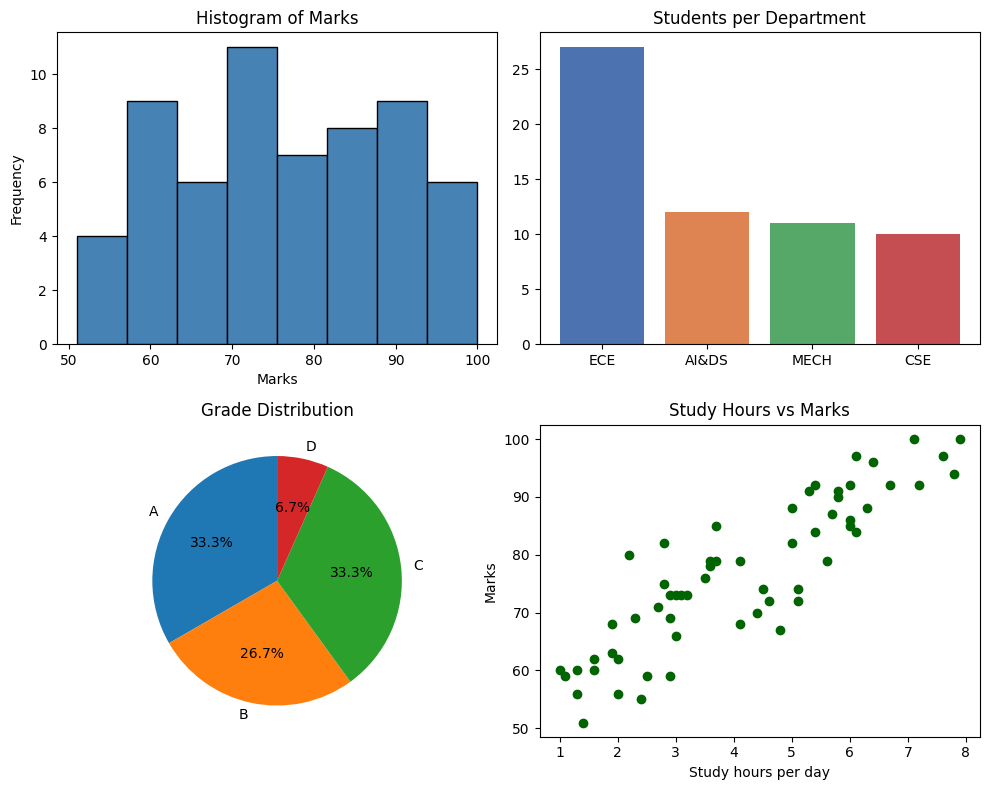


Plot saved as exp03_eda.png


In [7]:
# Exp 3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ---------- Step 1: Generate Student Dataset ----------

np.random.seed(7)
n = 60

students = pd.DataFrame(
    {
        "roll_no": range(1, n + 1),

        "gender": np.random.choice(
            ["Male", "Female"], n
        ),

        "department": np.random.choice(
            ["CSE", "ECE", "MECH", "AI&DS"],
            n,
            p=[0.3, 0.25, 0.2, 0.25]
        ),

        "grade": np.random.choice(
            ["A", "B", "C", "D"],
            n,
            p=[0.25, 0.4, 0.25, 0.1]
        ),

        "attendance": np.random.randint(60, 100, n),

        "study_hours": np.round(
            np.random.uniform(1, 8, n), 1
        ),
    }
)

# Calculate student marks
students["marks"] = np.clip(
    (
        35
        + 6 * students["study_hours"]
        + 0.2 * students["attendance"]
        + np.random.normal(0, 6, n)
    ).round(),
    0,
    100,
).astype(int)


# ---------- Step 2: Display Student Records ----------

print("Student Performance: Exploratory Data Analysis")
print("=" * 50)

print("\nFirst 5 records:")
print(students.head().to_string(index=False))


# ---------- Step 3: Classification of Data ----------

data_types = {
    "roll_no": "Nominal (identifier)",
    "gender": "Qualitative - Nominal",
    "department": "Qualitative - Nominal",
    "grade": "Qualitative - Ordinal",
    "attendance": "Quantitative - Discrete",
    "study_hours": "Quantitative - Continuous",
    "marks": "Quantitative - Discrete",
}

print("\nClassification of attributes:")

for col, t in data_types.items():
    print(f"  {col:<12} : {t}")


# ---------- Step 4: Descriptive Statistics ----------

num = students[
    ["attendance", "study_hours", "marks"]
]

print("\nSummary statistics:")
print(num.describe().round(2).to_string())

print("\nMedian:", num.median().to_dict())

print(
    "Mode of grade:",
    students["grade"].mode()[0]
)

print(
    "Skewness of marks:",
    round(students["marks"].skew(), 3)
)


# ---------- Step 5: Frequency Table ----------

print("\nFrequency table - department:")

print(
    students["department"]
    .value_counts()
    .to_string()
)


# ---------- Step 6: Cross Table ----------

print("\nCross table - department vs grade:")

print(
    pd.crosstab(
        students["department"],
        students["grade"]
    ).to_string()
)


# ---------- Step 7: Correlation Matrix ----------

print("\nCorrelation matrix:")

print(
    num.corr()
    .round(3)
    .to_string()
)


# ---------- Step 8: Graphical Presentation ----------

fig, ax = plt.subplots(
    2, 2,
    figsize=(10, 8)
)


# Graph 1: Histogram of Marks

ax[0, 0].hist(
    students["marks"],
    bins=8,
    color="steelblue",
    edgecolor="black"
)

ax[0, 0].set_title("Histogram of Marks")
ax[0, 0].set_xlabel("Marks")
ax[0, 0].set_ylabel("Frequency")


# Graph 2: Students per Department

dept = students["department"].value_counts()

ax[0, 1].bar(
    dept.index,
    dept.values,
    color=[
        "#4c72b0",
        "#dd8452",
        "#55a868",
        "#c44e52"
    ]
)

ax[0, 1].set_title("Students per Department")


# Graph 3: Grade Distribution

grade = students["grade"].value_counts().sort_index()

ax[1, 0].pie(
    grade.values,
    labels=grade.index,
    autopct="%1.1f%%",
    startangle=90
)

ax[1, 0].set_title("Grade Distribution")


# Graph 4: Study Hours vs Marks

ax[1, 1].scatter(
    students["study_hours"],
    students["marks"],
    c="darkgreen"
)

ax[1, 1].set_title("Study Hours vs Marks")
ax[1, 1].set_xlabel("Study hours per day")
ax[1, 1].set_ylabel("Marks")


# Adjust graph layout
plt.tight_layout()


# Save and display graphs
plt.savefig(
    "exp03_eda.png",
    dpi=150
)

plt.show()

print("\nPlot saved as exp03_eda.png")

In [8]:
# Exp 4
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# ---------- Step 1: Generate Customer Dataset ----------

np.random.seed(42)
n = 200

df = pd.DataFrame(
    {
        "customer_id": range(1001, 1001 + n),

        "age": np.random.randint(18, 70, n).astype(float),

        "income": np.random.normal(
            45000, 12000, n
        ).round(),

        "city": np.random.choice(
            ["Chennai", "chennai ", "Madurai", "Coimbatore"],
            n
        ),

        "purchases": np.random.poisson(
            6, n
        ).astype(float),

        "churn": np.random.choice(
            ["Yes", "No"],
            n,
            p=[0.3, 0.7]
        ),
    }
)


# ---------- Step 2: Inject Data Quality Problems ----------

# Missing values
df.loc[
    np.random.choice(n, 15, replace=False),
    "age"
] = np.nan

df.loc[
    np.random.choice(n, 10, replace=False),
    "income"
] = np.nan

# Outliers and invalid values
df.loc[[5, 50, 120], "income"] = [
    450000, 520000, -3000
]

# Add duplicate records
df = pd.concat(
    [df, df.iloc[[10, 20, 30, 40, 50]]],
    ignore_index=True
)


# ---------- Step 3: Display Raw Dataset ----------

print("Customer Data: Cleaning and Sampling for Modeling")
print("=" * 50)

print("Raw shape:", df.shape)


# ---------- Step 4: Handle Missing Values ----------

print("\n[1] Missing values per column:")
print(df.isnull().sum().to_string())


# ---------- Step 5: Remove Duplicate Records ----------

dups = df.duplicated().sum()

df = df.drop_duplicates()

print(
    f"\n[2] Duplicate rows removed: {dups} "
    f"-> shape {df.shape}"
)


# ---------- Step 6: Correct Inconsistent Categories ----------

print(
    "\n[3] City values before:",
    sorted(df["city"].unique())
)

df["city"] = (
    df["city"]
    .str.strip()
    .str.title()
)

print(
    "    City values after :",
    sorted(df["city"].unique())
)


# ---------- Step 7: Handle Invalid Values and Outliers ----------

df.loc[
    df["income"] < 0,
    "income"
] = np.nan

q1, q3 = df["income"].quantile([0.25, 0.75])

iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

outliers = df[
    (df["income"] < low) |
    (df["income"] > high)
]

print(
    f"\n[4] Income IQR bounds: {low:.0f} to {high:.0f}"
)

print("    Outliers found:", len(outliers))

print(
    outliers[
        ["customer_id", "income"]
    ].to_string(index=False)
)

# Replace outliers using clipping
df["income"] = df["income"].clip(low, high)


# ---------- Step 8: Imputation ----------

df["age"] = df["age"].fillna(
    df["age"].median()
)

df["income"] = df["income"].fillna(
    df["income"].mean()
).round()

print(
    "\n[5] Missing values after imputation:",
    int(df.isnull().sum().sum())
)


# ---------- Step 9: Encoding and Scaling ----------

# Convert churn categories into numerical values
df["churn"] = df["churn"].map(
    {"No": 0, "Yes": 1}
)

# Convert city categories into dummy variables
df = pd.get_dummies(
    df,
    columns=["city"],
    drop_first=True,
    dtype=int
)

# Standardize numerical features
scaler = StandardScaler()

df[["age", "income", "purchases"]] = scaler.fit_transform(
    df[["age", "income", "purchases"]]
)

print("\n[6] Cleaned and transformed data (first 5 rows):")

print(
    df.head()
    .round(3)
    .to_string(index=False)
)


# ---------- Step 10: Simple Random Sampling ----------

X = df.drop(
    columns=["customer_id", "churn"]
)

y = df["churn"]

simple = df.sample(
    frac=0.2,
    random_state=1
)

print(
    "\n[7] Simple random sample (20%):",
    len(simple),
    "rows, churn rate =",
    round(simple["churn"].mean(), 3)
)


# ---------- Step 11: Train, Validation and Test Split ----------

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=1
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state=1
)


# ---------- Step 12: Display Sampling Results ----------

print(
    "\nStratified Train / Validation / Test split (70/15/15):"
)

for name, part in [
    ("Overall", y),
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test),
]:
    print(
        f"  {name:<11} rows = {len(part):>3}   "
        f"churn rate = {part.mean():.3f}"
    )


Customer Data: Cleaning and Sampling for Modeling
Raw shape: (205, 6)

[1] Missing values per column:
customer_id     0
age            16
income         10
city            0
purchases       0
churn           0

[2] Duplicate rows removed: 5 -> shape (200, 6)

[3] City values before: ['Chennai', 'Coimbatore', 'Madurai', 'chennai ']
    City values after : ['Chennai', 'Coimbatore', 'Madurai']

[4] Income IQR bounds: 11224 to 79240
    Outliers found: 4
 customer_id   income
        1006 450000.0
        1051 520000.0
        1073  10447.0
        1171  83244.0

[5] Missing values after imputation: 0

[6] Cleaned and transformed data (first 5 rows):
 customer_id    age  income  purchases  churn  city_Coimbatore  city_Madurai
        1001  0.877   0.095      0.760      0                0             1
        1002  1.785  -1.211     -0.418      0                0             0
        1003  0.179   1.821     -1.203      0                1             0
        1004 -0.799  -0.171     -0.41